Overview:

Design Assumptions:
- Sister cells of bacteria that have lost their plasmid do not enter a new death curve upon replication, they maintain the same probability of survival as the parent.
- Plasmid loss rate is a constant proportionate to the density of plasmid-containing bacteria. The proportional rate does not increase or decrease with variation in population density or potential other factors. 
- Curve for OD600 is directly representational of doubling time. If doubling time changes over the growth curve, we look for the average doubling time represented by 
- Bacteria are plated immediately after reaching OD600 of 0.4
- For the growth curve of bacteria with plasmids under antibiotic selection, PFB do not contribute to the growth curve(this is not true, but does not affect results by a lot. For proper implementation you want to correct for this though)
- All entries in data files are tab delimited(it does seem like this is the case in files that were provided)
- Growth curve for pcb selected for by carbenecillin (100 µg/mL) is not significantly different from if it were selected for by kanamycin
- Only two experimental treatments are given
- An increase in OD600 does indicate growth

Future improvements:
- Account for influence of PFB in growth curve and correct accordingly(marginal increase in accuracy of estimates)
- Visualization of methodology/approach
- Decide best doubling time use 
- Deal with less consistent file inputs
- More efficient code: proportions and plasmid loss rates are directly proportional based on this equation, so binary search can probably be removed. However, if model turns out to need updating in a way where plasmid loss isn't directly proportional, this gives me more flexibility for now
- Account for variance in data beyond final proportion replicates
- Even though there could be replication from plasmid-less bacteria in exposure to antibiotic as shown in OD.txt, this may not translate to CFU in final proportions. If that reasoning is correct, then current program may marginally under?estimate plasmid loss rate, especially in carbenicillin


(Rough) Design

For parsing the data:
    Open data file, split by tab into lists, and add all those lists to make a list of row-lists
    Make data to correspond to columns, with each column being formed by entries in rows sharing same index
    Average data for where multiple trials were conducted for the same treatment. Account for nonentries where data was not given for a specific hour value, so as to not raise any type/value errors

For computing the plasmid loss rate:


For each time step
PCBn= (PCBn-1 - t * PCBn-1 * L)(2**(t/d))
PFBn = PFBn-1 + t * PCBn-1 * r * p
For antibiotic interval(a), doubling time(d), replication of bacteria who lose their plasmids(r), probability of survival for time of remaining exposure(p), time step(t), and hypothetical loss rate(L), plasmid-containing bacteria population for current population(PCBn), plasmid-containing bacteria population at time step before current time step(PCBn-1), and corresponding time step notation for plasmid-free bacteria population(PFB)

Then calculate total proportion of PFB at hypothetical plating time, and bisection to find loss rate that results in proportions matching experimental data

    Outline:
        Get the doubling time, and neutralizing time for each antibiotic
        For the neutralizing time, compile a list of time steps that will be iterated through, where the above equations are applied to PCB and PFB equations for the difference between each time steps, and their proportions are then successively modified for each time steps
        Proportions is compared to experimental data. Program continues until proportions are sufficiently close to experimental proportions, and then returns plasmid loss rate used to compute those proportions for each treatment

Plasmid loss rate for Kanamycin = 0.13 ± 0.06 / hour
Plasmid loss rate for Carbenicillin = 0.35 ± 0.16 / hour


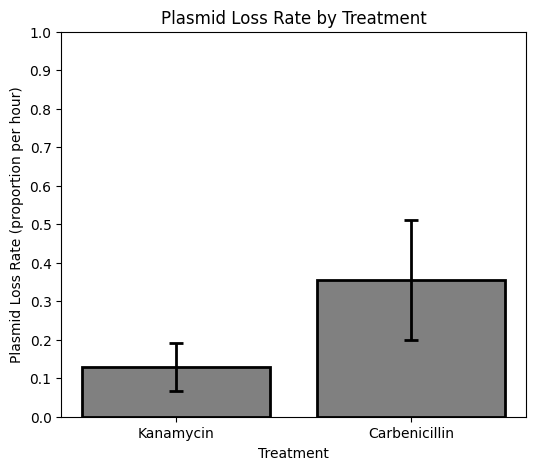

In [1]:
#!/usr/bin/env python3
# Viraj Arora

import math
import matplotlib.pyplot as plt

class ProcessTrialData():
    '''Takes one tab-delimited data file, sorts into columns and combines columns with the same header(representing multiple trials for one treatment) into their averages, 
        and returns processed data
        switch to pandas'''
    def __init__(self, filename):
        self.file = filename
        self.dataPerLine = [] # list of row-lists
        self.dataColumns = [] # list of column-lists
        self.finalArray = [] # final array to be returned to be used for compututations
        self.dataWidth = 0 
        self.dataLength = 0
    
    def parseRaw(self):
        '''parses file into a list of lists, where each list is a row of the data'''
        with open(self.file, 'r') as data:
            lines = [line.strip('\n').split('\t') for line in data if line.strip()] # creates a list of lists per row, split by tab
            self.dataPerLine.extend(lines)
        self.dataWidth = len(self.dataPerLine[0])
        self.dataLength = len(self.dataPerLine)
        
    def sortData(self):
         '''parses dataPerLine into a list of lists, where each lists is a column of data'''
         self.parseRaw()
         self.dataColumns = [[] for i in range(self.dataWidth)]
         for line in self.dataPerLine:
                for entryNum in range(self.dataWidth):
                    self.dataColumns[entryNum].append(line[entryNum])
         return self.dataColumns
                       
    def getFinalData(self):
        '''calls helper methods, then checks if columns share a header, and if so averages values'''
        self.sortData()
        headers = [] # creates a list of all unique headers found
        foundHeads = [] # creates a list of all headers found, regardless of uniqueness for the convenience of checking counts later

        # accumulates the same treatments and counts number of trials per experiment 
        for column in self.dataColumns:
            if column[0] not in headers:
                headers.append(column[0])
                foundHeads.append(column[0])
                self.finalArray.append(column)
            else:
                foundHeads.append(column[0])
                for headCheck in range(len(self.finalArray)):
                    if self.finalArray[headCheck][0] == column[0]:
                        for i in range(1, self.dataLength):
                            try:
                                self.finalArray[headCheck][i] = float(self.finalArray[headCheck][i]) + float(column[i])
                            except:
                                pass

        # divides trials for each treatment per count to average
        for trial in self.finalArray:
            headerCount = foundHeads.count(trial[0])
            for entry in range(1, self.dataLength):
                try:
                    trial[entry] = float(trial[entry]) / headerCount
                except:
                    pass
        return self.finalArray

class FindPlasmidLoss():
    '''finds the plasmid loss rate for each treatment given
        assumes that the same doubling rate is maintained until an OD of 0.4 for growth curve of bacteria '''
    def __init__(self, ODpcb, death, ODpfb, replicate):
        self.ODpcb = ODpcb # this is the data that shows the growth curve of transformed bacteria containing the plasmid
        self.death = death # data that shows survival rates for time after exposure to antibtiotic treatment for non-transformed bacteria
        self.ODpfb = ODpfb # this data shows the OD600 of bacteria who haven't been transformed after exposure to antibiotic
        self.replicate = replicate # final proportion of plasmid-free bacteria upon plating for each treatment
        self.killTimes = [] # kill times for each treatment in format [treatment, kill time] - if treatment did not kill, kill time will look funny, but we ignore it
        self.double = [] #  doubling time per interval - format is [time1, time2, doubling time]
        self.convDoub = 0 # placeholder double, will improve code later to deal with intervals. This just uses the last dT calc'd
    
    def getKillTimes(self):
        '''Gets kill time for each treatment as the time at which CFU hits minimum. This program assumes that minimum is close to 0 (<0.1% CFU)'''
        timeCol = self.death[0]  #time column of death curve data
        treatments = [] # format [treatment, killTime]

        # gets lowest value and the time it occurs at for the death curve of each treatment
        for col in self.death[1:]: # excludes hour column, since the goal is to loop through treatment data
            treatmentLabel = col[0]
            minVal = float(99999) # set to arbitrary high number, but eventually will be set to lowest CFU in one treatment's averages
            minIndex = -1 # set to arbitrary number initially, but will be set to time of minimum value
            

            for i in range(1, len(col)):  # cycles through values in column besides header

                # if value can be converted to a float, stores and compares to minVal
                try:
                    val = float(col[i]) 
                    if val < minVal:
                        minVal = val
                        minIndex = i
                except:
                    continue

            # if a minimum CFU value is found, gets the hour value for which the min value corresponds to in hour column
            if minIndex > 0:
                try:
                    killTime = float(timeCol[minIndex])
                except:
                    killTime = 0.0
            else:
                killTime = 0.0 # default kill time of 0.0 if there is no true minimum value found

            treatments.append([treatmentLabel, killTime])  

        self.killTimes = treatments 

    def setDuration(self, kTime): 
        '''uses a set timestep to compile a list of all time steps that will eventually be used for the final calc
        '''
        steps = []
        i = 0

        # creates a list for every time step for the length of antibiotic neutralization time
        while i <= kTime: 
            steps.append(i)
            i+= 0.01 # length of timestep, in hours
        return steps

    def getDoublingTime(self):
        '''gets doublingTime of "Top10 + pGFPuv WT"
            assumes that there is data for all points and that there are no 0 values
        '''
        relevantCol = [] # will be a list of lists with format of lists as [time, OD600]
        for curve in self.ODpcb:
            if curve[0] == "Hours":
                timePoints = curve[1:]
            if curve[0] == '"Top10 + pGFPuv WT"':
                odValues = curve[1:]
                relevantCol = [[float(timePoints[i]), float(odValues[i])] for i in range(len(timePoints))]
                break

        for i in range(1, len(relevantCol)):
            t1, od1 = relevantCol[i-1]
            t2, od2 = relevantCol[i]

            dT = (t2 - t1) / math.log2(od2 / od1) # calculates doubling time(dT) by getting time difference(t) and growth/fold change(fC), and plugging into equation based off of fC = 2^(t/dT)

            self.double.append([od1, od2, dT]) 
        self.convDoub = self.double[-1][2] # placeholder value for now, since sorting through doubling times to select the most appropriate one for   each calculation would provide marginal accuracy increases (doubling time for last interval in data set)
    
    def calcProps(self, lossRate):
        proportions = [] 
        for treatment in self.killTimes: # cycles through treatment, containing killTime info
            if treatment[0] != self.replicate[0]:
                continue
            killTime = float(treatment[1])
            if killTime > 0: # ignores the "No Drug" treatment (probably redundant now since iteration is skipped if treatment does not match replicate title)

                # stores initial value. It doesn't matter what pcbProp is set to, it's arbitrary as long as it's positive and a float
                pcbProp = 1 
                pfbProp = 0

                # cycles through every time step
                killSteps = self.setDuration(killTime)
                for i in range(1, len(killSteps)):
                    x2 = killSteps[i]
                    x1 = killSteps[i-1]
                    t = x2 - x1 # length of timestep

                    tTilD = killSteps[-1] - killSteps[i-1] # calculates time until end of exposure
                    
                    iniOD = 0 # initial OD value ODpfb, but will be modified in upcoming loop to reflect OD at t=0 for OD curve of pfb in antibiotc
                    bP = [0,9999,0,99999]
                    maxODcb = 0
                    maxODkan = 0

                    # gets the interval for which tilD falls between, so program can later calc slope to approximate replication for timeTilD
                    for header in self.ODpfb:
                        if header[0] == treatment[0]:
                            iniOD = header[1]
                            listOfPoints = [] # format [t1, t2, od1, od2]
                            for i in range(1, len(header)):
                                for ind in range(i + 1, len(header)):
                                    if header[i] and header[ind]:
                                        if (self.ODpfb[0][i] < tTilD) and (self.ODpfb[0][ind] > tTilD):
                                            listOfPoints.append([self.ODpfb[0][i], self.ODpfb[0][ind], header[i], header[ind]])
                            bP = [0,99999,0,9999]

                            #sets bP to the pair of coordinates with the smallest time difference
                            for p in listOfPoints:
                                if (p[1] - p[0]) < (bP[1] - bP[0]):
                                    bP = p
                            
                            # sets maxODs for each treatment
                            for point in header:
                                if treatment[0] == "Carbenicillin":
                                    try: 
                                        if float(point) > maxODcb:
                                            maxODcb = point
                                    except:
                                        pass
                                else:
                                    try: 
                                        if float(point) > maxODkan:
                                            maxODkan = point
                                    except:
                                        pass
                    t1 = bP[0]
                    t2 = bP[1]
                    od1 = bP[2]
                    od2 = bP[3]
                    repSlope = (od2 - od1) / (t2 - t1) # calcs slope between the two points tTilD falls between
                    pfbRep = 1

                    # gets expected rep per pfb with given tTilD
                    if repSlope > 0:
                        pfbRep = (od1 + (tTilD - t1) * repSlope) / iniOD
                    else:
                        if treatment[0] == "Carbenicillin": 
                            pfbRep = maxODcb / iniOD
                        else: # this does not actually ever get input because the neutralization time of kan is shorter than the time it takes to reach a max OD
                            pfbRep = maxODkan / iniOD
                    
                    # gets interval which tTilD falls betweeen for death curve in similar fashion as for ODpfb. Needed to do this because empty entries ended up making things weird
                    bestPoint = [0,99999,0,9999] 
                    for header in self.death:
                        if header[0] == treatment[0]:
                            listOfPoints = [] # format [t1, t2, cfu1, cfu2]
                            for i in range(1, len(header)):
                                for ind in range(i + 1, len(header)):
                                    if header[i] and header[ind]:
                                        if (self.death[0][i] < tTilD) and (self.death[0][ind] > tTilD):
                                            listOfPoints.append([self.death[0][i], self.death[0][ind], header[i], header[ind]])
                            bestPoint = [0,99999,0,9999]
                            for point in listOfPoints:
                                if (point[1] - point[0]) < (bestPoint[1] - bestPoint[0]):
                                    bestPoint = point
                    
                    deathSlope = (bestPoint[3] - bestPoint[2]) / (bestPoint[1] - bestPoint[0]) # gets the slope for current tTilD
                    pfbProb = (bestPoint[2] + (tTilD - bestPoint[0])*deathSlope) / 100 # gets probability of survival for current tTilD fpr pfb
                    pfbProp = pfbProp + t*lossRate*pcbProp*pfbProb*pfbRep # calculates the amount of pfb present for current timestep relative to initial pcb
                    pcbProp = pcbProp - t*lossRate*pcbProp # calculates the amount of pcb converted to pfb in last time step
                    pcbProp = pcbProp * (2**(t / self.convDoub)) # factors growth in for pcb
                treatProp = pfbProp / (pfbProp + pcbProp) # gets proportion of pfb
                proportions.append([treatment[0], treatProp])
        return proportions # format is [treatment, prop]
        
    def lfPlasmidLR(self):
        '''uses a binary search and helper methods to find experimental plasmid loss rates for treatments'''
        self.getKillTimes(); self.getDoublingTime()
        lossRates = [] # format is [treatment, lossRate]

        # cycles through treatments, performs binary search by calling calcProps method with each search
        for treatment in ["Kanamycin", "Carbenicillin"]: 
            currentProp = 1 
            
            if treatment == self.replicate[0]:
                currentProp = self.replicate[1] / 100 # divides replicate value by 100 to convert to a proportion
            else:
                continue
            high = 0.999
            low = 0.001
            precision = 0.001 # accuracy threshhold for matching experimental proportion 
            while(high - low) > precision:
                mid = (high + low)/ 2
                props = self.calcProps(mid)
                for prop in props:
                    if prop[0] == treatment:
                        if prop[1] > currentProp:
                            high = mid # if proportion is too big, then we want to decrease high since higher plasmid loss rates increase proportion of pfb
                        else:
                            low = mid 
            lossRates.extend([treatment, ((high + low) / 2)])
        return lossRates

def main():
    '''Uses the set file names to create objects in classes of this program, and call appropriate methods to get plasmid loss rate for both treatments'''
    odpcbFile = "Growth_curve.txt"
    deathFile = "NORMALIZED_CFU_vs_time.txt"
    odpfbFile = "OD.txt"
    propdarkFile = "pGFPck_plasmidLoss_carb_vs_kan.txt"

    # parses files and sorts file data into lists of columns
    odpcb = ProcessTrialData(odpcbFile).getFinalData()
    death = ProcessTrialData(deathFile).getFinalData()
    odpfb = ProcessTrialData(odpfbFile).getFinalData()
    propDark = ProcessTrialData(propdarkFile).sortData()

    results = []
    for replicate in propDark:
        treatment, value = replicate[0], float(replicate[1])
        getPL = FindPlasmidLoss(odpcb, death, odpfb, [treatment, value]) # get PL is an instance of class findPlasmidLoss
        results.append(getPL.lfPlasmidLR())

    resultTotals = {} # will carry treatment as the key and mean for each treatment for the value assigned to the key
    resultCounts = {} # will have treatment as the key and the number of replicates for each treatment assigned to the key

    # accumulates loss rates and number of replicates for each treatment
    for treatment, rate in results:
        if treatment not in resultTotals:
            resultTotals[treatment] = rate
            resultCounts[treatment] = 1
        else:
            resultTotals[treatment] += rate
            resultCounts[treatment] += 1
    
    # sets resultTotals for each treatment to reflect mean plasmid loss rates
    for treatment in resultTotals:
        resultTotals[treatment] = resultTotals[treatment] / resultCounts[treatment]
    
    # gets sample standard deviation for each treatment
    standardDevs = {}
    for treatment, rate in results:
        if treatment not in standardDevs:
            standardDevs[treatment] = (rate - resultTotals[treatment])**2
        else:
            standardDevs[treatment] += (rate - resultTotals[treatment])**2
    for treatment in standardDevs:
        if resultCounts[treatment] > 1:
            standardDevs[treatment] = math.sqrt(standardDevs[treatment] / (resultCounts[treatment] - 1))
        else:
            standardDevs[treatment] = 0

    # prints the found plasmid loss rate for each treatment, ± its sample std dev
    for treatment in resultTotals:
        print("Plasmid loss rate for {} = {:.2f} ± {:0.2f} / hour".format(treatment, resultTotals[treatment], standardDevs[treatment]))
    
    plt.figure(figsize=(6, 5))
    treatments = list(resultTotals.keys()) 
    means = [resultTotals[result] for result in treatments]
    std_devs = [standardDevs[result] for result in treatments]
    bars = plt.bar(
    treatments, 
    means,
    yerr = std_devs, # sets error bar to standard deviation
    capsize = 5,
    edgecolor = 'black',
    linewidth = 2,
    color = "gray",
    error_kw={'elinewidth': 2, 'capthick': 2}
    )
    plt.xlabel("Treatment")
    plt.ylabel("Plasmid Loss Rate (proportion per hour)")
    plt.title("Plasmid Loss Rate by Treatment")
    plt.ylim(0, 1)
    plt.yticks([i * 0.1 for i in range(11)])
    plt.savefig("plasmid_loss_rates.png", dpi=300) 
    plt.show()

if __name__ == "__main__":
    main()

Sample results for varying parameters - While program is currently set to give values to the hundredth, sample outputs are given to the thousandth to give a better idea of the effect of variance for different program parameters


Data as given, precision set to 0.001, and time steps set to 0.01 hours:

    Plasmid loss rate for Kanamycin = 0.129 ± 0.062/ hour 
    Plasmid loss rate for Carbenicillin = 0.355 ± 0.155/ hour


Data as given, precision set to 0.00001, time steps set to 0.01 hours:

    Plasmid loss rate for Kanamycin = 0.129 ± 0.062/ hour 
    Plasmid loss rate for Carbenicillin = 0.355 ± 0.155/ hour


Data as given, precision set to 0.1, time steps set to 0.01 hours:

    Plasmid loss rate for Kanamycin = 0.126 ± 0.044/ hour 
    Plasmid loss rate for Carbenicillin = 0.344 ± 0.176/ hour


Data as given, precision set to 0.001, time steps set to 0.05 hours:

    Plasmid loss rate for Kanamycin = 0.140 ± 0.067/ hour 
    Plasmid loss rate for Carbenicillin = 0.365 ± 0.158/ hour

Data as given, precision set to 0.001, time steps set to 0.001 hours:

    Plasmid loss rate for Kanamycin = 0.125 ± 0.060/ hour 
    Plasmid loss rate for Carbenicillin = 0.352 ± 0.154/ hour

Data as given, precision set to 0.001, time steps set to 0.1 hours:

    Plasmid loss rate for Kanamycin = 0.190 ± 0.090/ hour 
    Plasmid loss rate for Carbenicillin = 0.377 ± 0.161/ hour

Data as given, precision set to 0.001, time steps set to 0.01 hours, replication of plasmid free bacteria is not factored in:

    Plasmid loss rate for Kanamycin = 0.134 ± 0.064/ hour 
    Plasmid loss rate for Carbenicillin = 0.413 ± 0.178/ hour

Data as given, precision set to 0.001, time steps set to 0.1 hours, but doubling time is set to 1.396(doubling time for entire growth curve), as opposed to just for last interval(1.308, for t = 3.5 to t = 4.5):

    Plasmid loss rate for Kanamycin = 0.129 ± 0.062/ hour 
    Plasmid loss rate for Carbenicillin = 0.351 ± 0.154/ hour


Original input files
Growth_curve.txt
NORMALIZED_CFU_vs_time.txt
OD.txt
pGFPck_plasmidLoss_carb_vs_kan.txt